# AETHER — Poster Figures

Figures sized for an academic poster: larger type, heavier marks, and each one
standalone so it can be dropped into any column layout.

Each figure is written as `poster_<name>.png` at 600 dpi and 10 in wide, so it
scales down into any column. Set `POSTER_WIDTH` in the style cell to change that.

**The narrative is findings-forward**, in this order:

1. `poster_metric_decomposition` — **the hero.** Pooled AUROC on this dataset
   gives away ~0.32 to between-allele variation; a classical PSSM matches deep
   models once that is removed.
2. `poster_leakage` — why the shipped split cannot be used as-is.
3. `poster_dataset` — the 77% base rate that makes pooled metrics flattering.
4. `poster_benchmark` — all methods on the honest metric.
5. `poster_roc` — ROC curves.
6. `poster_architecture` — what AETHER is.
7. `poster_per_allele` — where it wins and loses.

Run `neoantigen.benchmark.run` first; this notebook reads its output.

In [1]:
from pathlib import Path
import json
import logging
import os
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# matplotlib reports a missing font through the logging module rather than
# warnings, so filterwarnings alone never silences "findfont: Font family
# 'Arial' not found".
warnings.filterwarnings("ignore", message=".*findfont.*")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------------------------------------------------------------
# plot style
# ---------------------------------------------------------------------
# Arial is the house font, but it ships with no Linux distribution and is not
# installed on this machine. Declaring a fallback chain means the figures use
# Arial wherever it exists and a metrically similar sans elsewhere, rather than
# matplotlib silently substituting whatever it has. Liberation Sans and Nimbus
# Sans share Arial's metrics, so text occupies the same space; DejaVu Sans is
# matplotlib's bundled last resort and is slightly wider.
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [
    "Arial", "Liberation Sans", "Nimbus Sans", "Helvetica", "DejaVu Sans",
]
mpl.rcParams["font.size"] = 10
DPI = 600
FIGSIZE = (6, 3.8)   # every figure stands alone; no subplots

BAR_COLOR = "#4b5563"
LIGHT_BAR_COLOR = "#d1d5db"
REF_LINE = "#6b7280"
GRID_COLOR = "#f0f0f0"

# ink scale for text that is not an axis label
INK = "#111827"
INK_SOFT = "#4b5563"
INK_MUTED = "#6b7280"

TAB = {"blue": "#4e79a7", "orange": "#f28e2b", "red": "#e15759", "teal": "#76b7b2",
       "green": "#59a14f", "yellow": "#edc948", "purple": "#b07aa1",
       "pink": "#ff9da7", "brown": "#9c755f", "gray": "#bab0ac"}

# roles, so a plot is written against what the color means
BINDER, NON_BINDER = TAB["blue"], TAB["orange"]
TRAIN_COLOR, VAL_COLOR = TAB["blue"], TAB["red"]
CLASS_COLORS = {"Binder": BINDER, "Non-binder": NON_BINDER}


def new_fig(figsize=FIGSIZE):
    """one standalone figure with its axes styled"""
    fig, ax = plt.subplots(figsize=figsize)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=GRID_COLOR, linewidth=0.6)
    ax.set_axisbelow(True)
    return fig, ax


def save_fig(fig, name):
    """600 dpi png into figures/, cropped to everything drawn"""
    path = FIG_DIR / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"saved {path}")


def left_legend(ax, handles, title, anchor):
    """left-aligned legend outside the axes; call again to stack another one below"""
    if ax.get_legend() is not None:
        previous = ax.get_legend()
        ax.add_artist(previous)
        previous.set_clip_on(False)
    legend = ax.legend(handles=handles, title=title, frameon=False,
                       bbox_to_anchor=anchor, loc="upper left")
    legend._legend_box.align = "left"
    legend.get_title().set_ha("left")
    return legend


def class_handles():
    return [Patch(facecolor=c, label=k) for k, c in CLASS_COLORS.items()]


# ---------------------------------------------------------------------
# paths, relative to this notebook
# ---------------------------------------------------------------------
FIG_DIR = Path.cwd()
REPO = FIG_DIR
while REPO != REPO.parent and not (REPO / "data").is_dir():
    REPO = REPO.parent
print("repo:", REPO)

# ---------------------------------------------------------------------
# poster style: same palette and conventions as the analysis notebooks,
# scaled up so a figure stays readable from a couple of metres away
# ---------------------------------------------------------------------
POSTER_WIDTH = 10.0          # inches; scale into any column width

mpl.rcParams.update({
    "font.size":        15,
    "axes.titlesize":   20,
    "axes.labelsize":   17,
    "xtick.labelsize":  14,
    "ytick.labelsize":  14,
    "legend.fontsize":  14,
    "axes.titleweight": "bold",
    "lines.linewidth":  3.0,
    "axes.linewidth":   1.4,
})


def poster_fig(height=6.0, width=POSTER_WIDTH):
    fig, ax = plt.subplots(figsize=(width, height))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=GRID_COLOR, linewidth=1.0)
    ax.set_axisbelow(True)
    return fig, ax


def save_poster(fig, name):
    """600 dpi PNG, 10 in wide — scales into any poster column."""
    path = FIG_DIR / f"poster_{name}.png"
    fig.savefig(path, dpi=600, bbox_inches="tight")
    print(f"saved {path}")


METHOD_COLORS = {
    "aether":              TAB["blue"],
    "esm2_probe":          TAB["orange"],
    "pssm":                TAB["green"],
    "blosum_lr":           TAB["teal"],
    "allele_length_prior": TAB["red"],
    "allele_prior":        TAB["purple"],
    "length_prior":        TAB["yellow"],
    "majority":            TAB["gray"],
    "pepmhc_archive":      TAB["brown"],
    "mhcflurry":           TAB["pink"],
    "netmhcpan":           BAR_COLOR,
}
METHOD_LABELS = {
    "aether":              "AETHER",
    "esm2_probe":          "ESM2 linear probe",
    "pssm":                "PSSM (per allele)",
    "blosum_lr":           "BLOSUM + logistic",
    "allele_length_prior": "Allele x length prior",
    "allele_prior":        "Allele prior",
    "length_prior":        "Length prior",
    "majority":            "Majority class",
    "pepmhc_archive":      "PepMHC (archived)",
    "mhcflurry":           "MHCflurry",
    "netmhcpan":           "NetMHCpan",
}
mcolor = lambda m: METHOD_COLORS.get(m, BAR_COLOR)
mlabel = lambda m: METHOD_LABELS.get(m, m)

repo: /home/vivian.chu/AETHER/figures/poster


In [2]:
BENCH_DIR = Path(os.environ.get("AETHER_BENCH_DIR") or (REPO / "outputs" / "benchmarks"))
DATA = REPO / "data" / "mhcattnnet" / "classI"

if not BENCH_DIR.exists():
    raise SystemExit(f"No benchmark output at {BENCH_DIR}. "
                     "Run `python -m neoantigen.benchmark.run ...` first.")

meta = json.loads((BENCH_DIR / "benchmark_meta.json").read_text())

# Methods left off the poster. They stay in the benchmark suite and in
# 03_benchmark_comparison.ipynb — this only controls what gets shown here.
POSTER_EXCLUDE = {"pepmhc_archive"}

preds, skipped = {}, []
for p in sorted(BENCH_DIR.glob("*_predictions.csv")):
    name = p.name.replace("_predictions.csv", "")
    if name in POSTER_EXCLUDE:
        skipped.append(name)
        continue
    preds[name] = pd.read_csv(p)

if skipped:
    print(f"excluded from poster figures: {', '.join(skipped)}")


def within_allele_auc(df, min_rows=50):
    """
    AUROC computed separately per allele, then averaged weighted by support.

    Between-allele differences in how often peptides bind contribute nothing
    here, so this isolates the only thing a binding model should be doing:
    ranking peptides against a fixed allele.
    """
    from sklearn.metrics import roc_auc_score
    d = df.dropna(subset=["y_pred_prob"])
    aucs, weights = [], []
    for _, g in d.groupby("mhc_allele"):
        y = (g["y_true"] >= 0.5).astype(int)
        if len(g) >= min_rows and y.nunique() == 2:
            aucs.append(roc_auc_score(y, g["y_pred_prob"]))
            weights.append(len(g))
    if not aucs:
        return np.nan, 0
    return float(np.average(aucs, weights=weights)), len(aucs)


from sklearn.metrics import roc_auc_score

stats = {}
for m, d in preds.items():
    dd = d.dropna(subset=["y_pred_prob"])
    y = (dd["y_true"] >= 0.5).astype(int)
    w, n_all = within_allele_auc(d)
    stats[m] = {
        "pooled": roc_auc_score(y, dd["y_pred_prob"]) if y.nunique() == 2 else np.nan,
        "within": w, "n_alleles": n_all,
    }
stats = pd.DataFrame(stats).T.sort_values("within", ascending=False)
HAS_AETHER = "aether" in stats.index
print(f"{len(stats)} methods | {meta['n_common']:,} rows | "
      f"{int(stats['n_alleles'].max())} alleles with >=50 rows")
if not HAS_AETHER:
    print("NOTE: no AETHER predictions in this benchmark dir — "
          "panels that need them will say so.")
stats.round(4)

8 methods | 34,803 rows | 66 alleles with >=50 rows


,pooled,within,n_alleles
aether,0.9639,0.9330,66.0
mhcflurry,0.9410,0.9202,66.0
pssm,0.9107,0.9008,66.0
esm2_probe,0.8673,0.7202,66.0
blosum_lr,0.8677,0.7100,66.0
allele_length_prior,0.8619,0.6580,66.0
allele_prior,0.8186,0.5000,66.0
majority,0.5000,0.5000,66.0


## 1. Hero — pooled vs within-allele AUROC

The single most important panel. `allele_prior` predicts one constant per allele
and never reads the peptide, yet scores 0.82 pooled — because 77% of rows are
binders and alleles differ in how often they bind. Strip that away and it is
exactly 0.50.

saved /home/vivian.chu/AETHER/figures/poster/poster_metric_decomposition.png


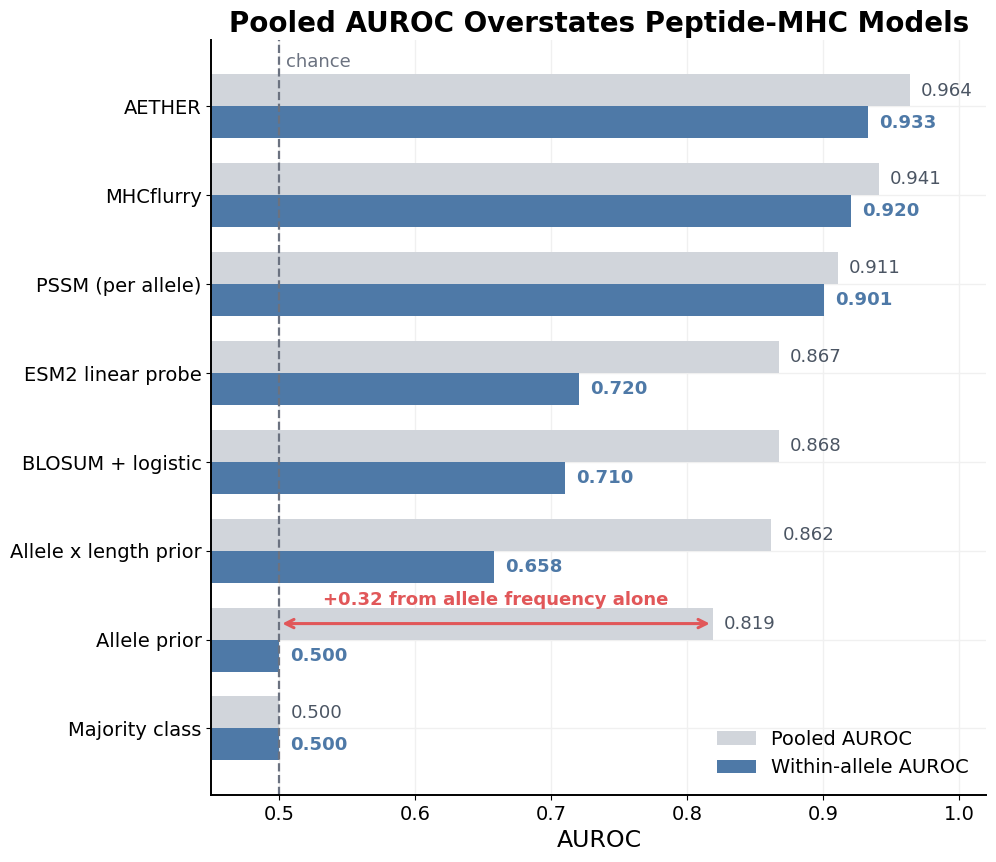

In [3]:
order = stats.sort_values("within", ascending=False).index.tolist()
y = np.arange(len(order))[::-1]
h = 0.36

fig, ax = poster_fig(height=0.95 * len(order) + 2.2)
ax.barh(y + h / 2, stats.loc[order, "pooled"], height=h,
        color=LIGHT_BAR_COLOR, label="Pooled AUROC")
ax.barh(y - h / 2, stats.loc[order, "within"], height=h,
        color=TAB["blue"], label="Within-allele AUROC")

for yi, m in zip(y, order):
    ax.text(stats.loc[m, "pooled"] + 0.008, yi + h / 2, f"{stats.loc[m, 'pooled']:.3f}",
            va="center", fontsize=13, color=BAR_COLOR)
    ax.text(stats.loc[m, "within"] + 0.008, yi - h / 2, f"{stats.loc[m, 'within']:.3f}",
            va="center", fontsize=13, color=TAB["blue"], fontweight="bold")

ax.axvline(0.5, color=REF_LINE, linestyle="--", linewidth=1.6)
ax.text(0.505, len(order) - 0.55, "chance", fontsize=13, color=REF_LINE)

# Call out the giveaway on the baseline that makes the point most starkly.
if "allele_prior" in stats.index:
    yi = y[order.index("allele_prior")]
    p, w = stats.loc["allele_prior", ["pooled", "within"]]
    ax.annotate("", xy=(p, yi + h / 2), xytext=(w, yi + h / 2),
                arrowprops=dict(arrowstyle="<->", color=TAB["red"], linewidth=2.2))
    # Keep the caption inside this row's half-step, or it reads as belonging to
    # the row above.
    ax.text((p + w) / 2, yi + h / 2 + 0.21,
            f"+{p - w:.2f} from allele frequency alone",
            ha="center", fontsize=13, color=TAB["red"], fontweight="bold")

ax.set_yticks(y, [mlabel(m) for m in order])
ax.set_xlabel("AUROC")
ax.set_xlim(0.45, 1.02)
ax.set_title("Pooled AUROC Overstates Peptide-MHC Models")
ax.legend(loc="lower right", frameon=False)

save_poster(fig, "metric_decomposition")
plt.show()

## 2. The leakage audit

Measured on the shipped class-I split. These are the numbers that motivate
`neoantigen.data.regroup`.

saved /home/vivian.chu/AETHER/figures/poster/poster_leakage.png


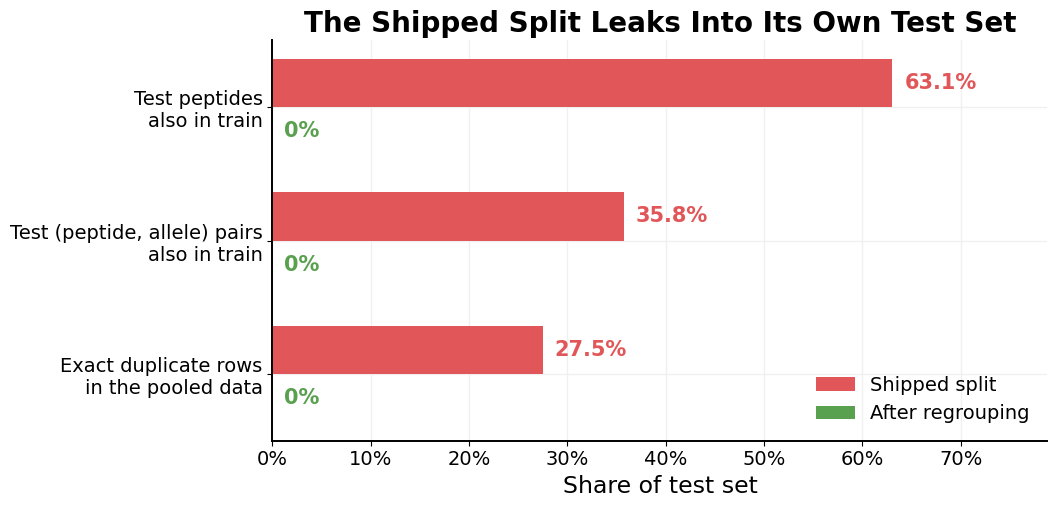

In [4]:
tr = pd.read_csv(DATA / "train.csv")
te = pd.read_csv(DATA / "test.csv")
pool = pd.concat([tr, pd.read_csv(DATA / "val.csv"), te], ignore_index=True)

pair = lambda d: set(zip(d.peptide, d.mhc_allele))
measured = {
    "Test peptides\nalso in train":        len(set(te.peptide) & set(tr.peptide)) / te.peptide.nunique(),
    "Test (peptide, allele) pairs\nalso in train": len(pair(te) & pair(tr)) / len(pair(te)),
    "Exact duplicate rows\nin the pooled data":    pool.duplicated().sum() / len(pool),
}

labels = list(measured)
orig = np.array(list(measured.values()))
y = np.arange(len(labels))[::-1]
h = 0.36

fig, ax = poster_fig(height=5.2)
ax.barh(y + h / 2, orig, height=h, color=TAB["red"], label="Shipped split")
ax.barh(y - h / 2, np.zeros(len(labels)), height=h, color=TAB["green"],
        label="After regrouping")

for yi, v in zip(y, orig):
    ax.text(v + 0.012, yi + h / 2, f"{v:.1%}", va="center", fontsize=15,
            fontweight="bold", color=TAB["red"])
    ax.text(0.012, yi - h / 2, "0%", va="center", fontsize=15,
            fontweight="bold", color=TAB["green"])

ax.set_yticks(y, labels)
ax.set_xlabel("Share of test set")
ax.set_xlim(0, max(orig) * 1.25)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("The Shipped Split Leaks Into Its Own Test Set")
ax.legend(loc="lower right", frameon=False)

save_poster(fig, "leakage")
plt.show()

## 3. Dataset — the base rate behind the inflated metrics

saved /home/vivian.chu/AETHER/figures/poster/poster_dataset.png


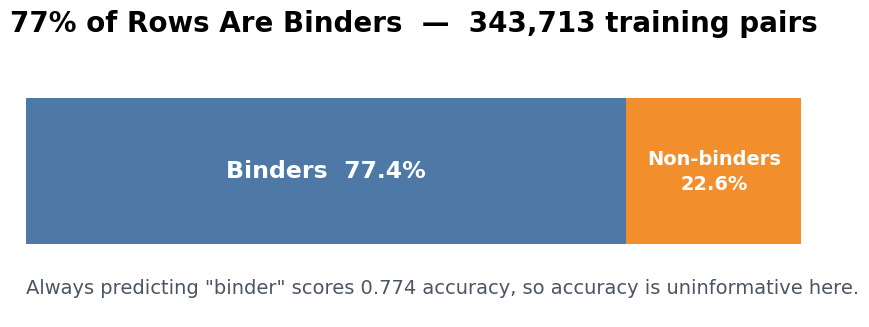

In [5]:
fig, ax = poster_fig(height=3.6)

pos = tr["bind"].mean()
ax.barh([0], [pos], height=0.5, color=BINDER)
ax.barh([0], [1 - pos], height=0.5, left=pos, color=NON_BINDER)
ax.text(pos / 2, 0, f"Binders  {pos:.1%}", ha="center", va="center",
        color="white", fontsize=17, fontweight="bold")
# Two lines: the non-binder segment is only ~22% of the width, and one line
# runs off the end of the axes.
ax.text(pos + (1 - pos) / 2, 0, f"Non-binders\n{1 - pos:.1%}", ha="center",
        va="center", color="white", fontsize=14, fontweight="bold",
        linespacing=1.4)

ax.set_xlim(0, 1)
ax.set_ylim(-0.5, 0.45)
ax.set_yticks([])
ax.set_xticks([])
ax.grid(False)
ax.spines[:].set_visible(False)
ax.set_title(f"77% of Rows Are Binders  —  {len(tr):,} training pairs")
ax.text(0, -0.42, 'Always predicting "binder" scores 0.774 accuracy, '
        'so accuracy is uninformative here.',
        fontsize=14, color=INK_SOFT)

save_poster(fig, "dataset")
plt.show()

## 4. Benchmark on the honest metric

saved /home/vivian.chu/AETHER/figures/poster/poster_benchmark.png


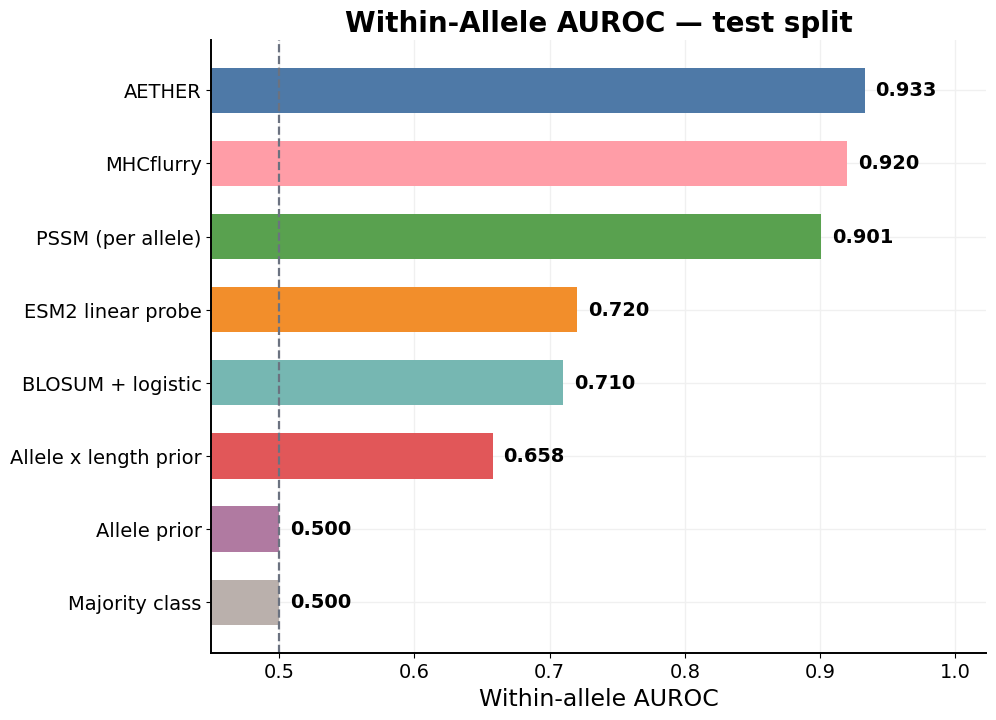

In [6]:
order_w = stats.sort_values("within", ascending=False).index.tolist()
y = np.arange(len(order_w))[::-1]

fig, ax = poster_fig(height=0.72 * len(order_w) + 2.2)
ax.barh(y, stats.loc[order_w, "within"], height=0.62,
        color=[mcolor(m) for m in order_w])
for yi, m in zip(y, order_w):
    ax.text(stats.loc[m, "within"] + 0.008, yi, f"{stats.loc[m, 'within']:.3f}",
            va="center", fontsize=14, fontweight="bold")

ax.axvline(0.5, color=REF_LINE, linestyle="--", linewidth=1.6)
ax.set_yticks(y, [mlabel(m) for m in order_w])
ax.set_xlabel("Within-allele AUROC")
ax.set_xlim(0.45, min(1.04, float(stats["within"].max()) + 0.09))
ax.set_title(f"Within-Allele AUROC — {meta['split']} split")

save_poster(fig, "benchmark")
plt.show()

## 5. ROC curves

saved /home/vivian.chu/AETHER/figures/poster/poster_roc.png


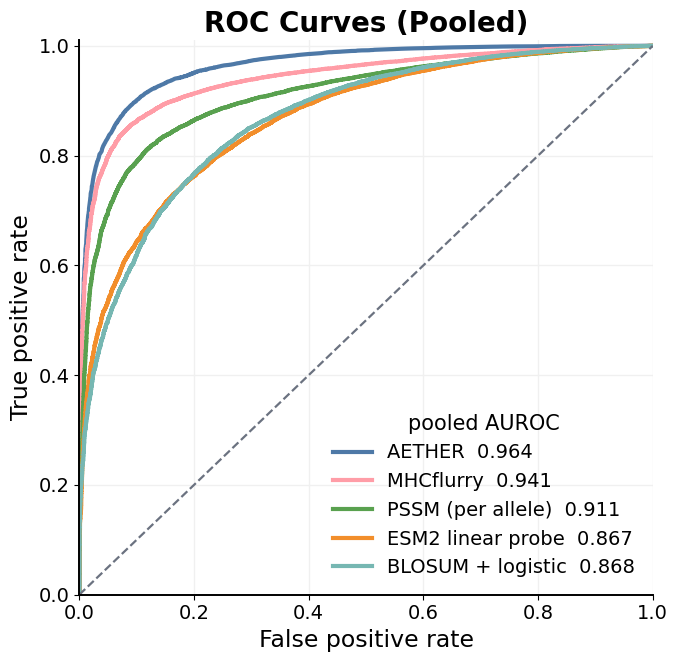

In [7]:
from sklearn.metrics import roc_curve

show = [m for m in order_w[:5] if m in preds]
if HAS_AETHER and "aether" not in show:
    show.append("aether")

fig, ax = poster_fig(height=7.2, width=7.4)
for m in show:
    d = preds[m].dropna(subset=["y_pred_prob"])
    yt = (d["y_true"] >= 0.5).astype(int)
    if yt.nunique() < 2:
        continue
    fpr, tpr, _ = roc_curve(yt, d["y_pred_prob"])
    ax.plot(fpr, tpr, color=mcolor(m), linewidth=3.0,
            label=f"{mlabel(m)}  {stats.loc[m, 'pooled']:.3f}")

ax.plot([0, 1], [0, 1], color=REF_LINE, linestyle="--", linewidth=1.6)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_title("ROC Curves (Pooled)")
ax.legend(loc="lower right", frameon=False, title="pooled AUROC")

save_poster(fig, "roc")
plt.show()

## 6. Architecture schematic

Drawn here rather than in a vector editor so it stays in sync with the model and
re-exports with the rest of the figures.

saved /home/vivian.chu/AETHER/figures/poster/poster_architecture.png


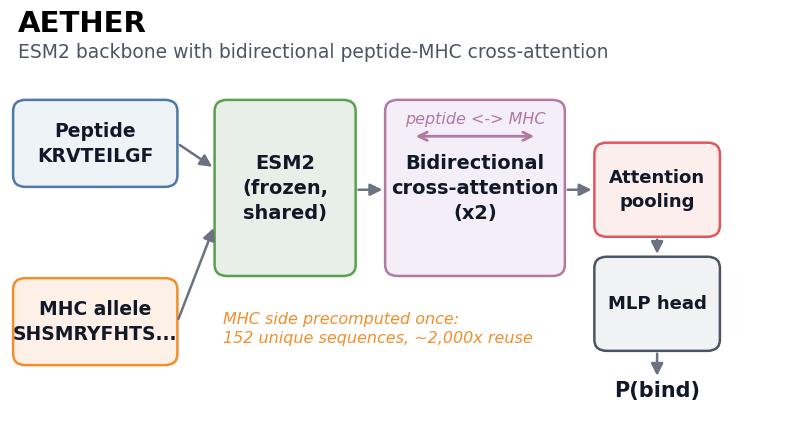

In [8]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(POSTER_WIDTH, 5.0))
ax.set_xlim(0, 100); ax.set_ylim(0, 54)
ax.axis("off")


def box(x, y, w, h, text, face, edge=None, fs=13, bold=False, tcolor=INK):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6,rounding_size=1.6",
                                facecolor=face, edgecolor=edge or face, linewidth=1.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            color=tcolor, fontweight="bold" if bold else "normal", linespacing=1.4)


def arrow(x1, y1, x2, y2, color=INK_MUTED, style="-|>"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=style,
                                 mutation_scale=18, color=color, linewidth=1.8))


# inputs
box(1, 34, 20, 11, "Peptide\nKRVTEILGF", "#eef3f8", TAB["blue"], fs=13.5, bold=True)
box(1, 9, 20, 11, "MHC allele\nSHSMRYFHTS...", "#fdf0e7", TAB["orange"], fs=13.5, bold=True)

# backbone
box(27, 21.5, 17, 23.5, "ESM2\n(frozen,\nshared)", "#e8efe8", TAB["green"],
    fs=14, bold=True)
arrow(21.6, 39.5, 26.4, 36)
arrow(21.6, 14.5, 26.4, 28)

# precompute callout on the MHC path, clear of the box borders above it
ax.text(27.5, 11.5, "MHC side precomputed once:\n152 unique sequences, ~2,000x reuse",
        fontsize=11.5, color=TAB["orange"], style="italic", linespacing=1.4)

# interaction — box widened so the longest label clears its own border
box(49, 21.5, 22, 23.5, "Bidirectional\ncross-attention\n(x2)", "#f3eef8",
    TAB["purple"], fs=14, bold=True)
arrow(44.6, 33, 48.4, 33)
ax.annotate("", xy=(68, 40.5), xytext=(52, 40.5),
            arrowprops=dict(arrowstyle="<->", color=TAB["purple"], linewidth=2.0))
ax.text(60, 42.2, "peptide <-> MHC", ha="center", fontsize=11.5,
        color=TAB["purple"], style="italic")

# pooling + head
box(76, 27, 15, 12, "Attention\npooling", "#fdeeee", TAB["red"], fs=13, bold=True)
box(76, 11, 15, 12, "MLP head", "#f1f2f4", BAR_COLOR, fs=13, bold=True)
arrow(71.6, 33, 75.4, 33)
arrow(83.5, 26.4, 83.5, 23.6)
arrow(83.5, 10.4, 83.5, 6.5)
ax.text(83.5, 4.0, "P(bind)", ha="center", fontsize=15, fontweight="bold",
        color=INK)

ax.set_title("AETHER", fontsize=21, fontweight="bold", loc="left", x=0.01)
ax.text(0.01, 0.955, "ESM2 backbone with bidirectional peptide-MHC cross-attention",
        transform=ax.transAxes, fontsize=13.5, color=INK_SOFT)

save_poster(fig, "architecture")
plt.show()

## 7. Per-allele — where the model wins and loses

saved /home/vivian.chu/AETHER/figures/poster/poster_per_allele.png


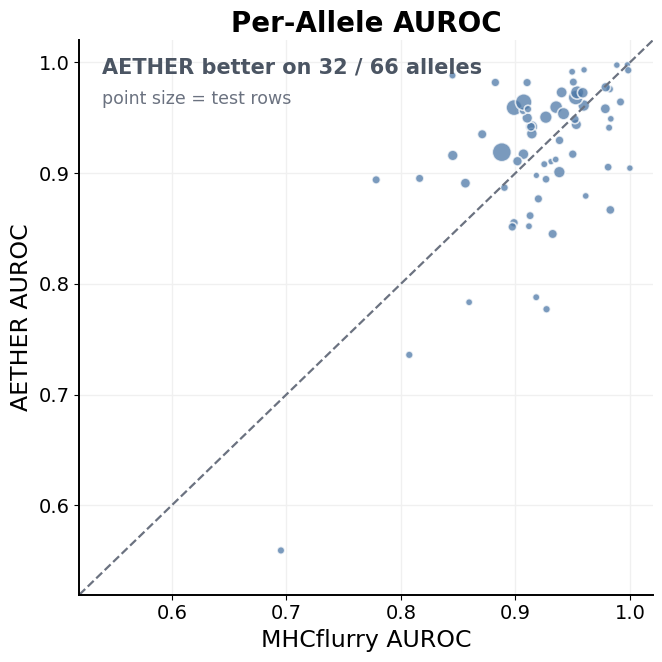

In [9]:
CHALLENGER = "aether"
reference = next((m for m in order_w if m != CHALLENGER), None)

if not HAS_AETHER:
    print("No AETHER predictions yet. Re-run the benchmark with\n"
          "  --include aether=outputs/<run>/test_predictions.csv\n"
          "once a training run has finished, then re-run this cell.")
else:
    # Pair row-for-row and drop anything either method declined, so both sides
    # of the diagonal are measured on identical rows.
    a, b = preds[CHALLENGER], preds[reference]
    paired = pd.DataFrame({
        "mhc_allele": a["mhc_allele"].to_numpy(),
        "y_true": a["y_true"].to_numpy(),
        "s_a": a["y_pred_prob"].to_numpy(),
        "s_b": b["y_pred_prob"].to_numpy(),
    }).dropna(subset=["s_a", "s_b"])

    rows = []
    for allele, g in paired.groupby("mhc_allele"):
        yg = (g["y_true"] >= 0.5).astype(int)
        if len(g) >= 50 and yg.nunique() == 2:
            rows.append({"allele": allele, "n": len(g),
                         "aether": roc_auc_score(yg, g["s_a"]),
                         "ref": roc_auc_score(yg, g["s_b"])})
    pa = pd.DataFrame(rows)

    fig, ax = poster_fig(height=7.2, width=7.4)
    lim = [min(pa[["aether", "ref"]].min()) - 0.04, 1.02]
    ax.plot(lim, lim, color=REF_LINE, linestyle="--", linewidth=1.6)
    ax.scatter(pa["ref"], pa["aether"], s=20 + 170 * pa["n"] / pa["n"].max(),
               color=TAB["blue"], alpha=0.75, edgecolor="white", linewidth=1.2)
    wins = int((pa["aether"] > pa["ref"]).sum())
    ax.text(0.04, 0.94, f"AETHER better on {wins} / {len(pa)} alleles",
            transform=ax.transAxes, fontsize=15, fontweight="bold", color=BAR_COLOR)
    ax.set_xlabel(f"{mlabel(reference)} AUROC")
    ax.set_ylabel("AETHER AUROC")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title("Per-Allele AUROC")
    ax.text(0.04, 0.885, "point size = test rows", transform=ax.transAxes,
            fontsize=12.5, color=INK_MUTED)

    save_poster(fig, "per_allele")
    plt.show()

## Exported files

In [10]:
for p in sorted(FIG_DIR.glob("poster_*.png")):
    print(f"{p.name:38s} {p.stat().st_size / 1e3:7.0f} KB")

poster_architecture.png                    406 KB
poster_benchmark.png                       404 KB
poster_dataset.png                         230 KB
poster_leakage.png                         393 KB
poster_metric_decomposition.png            600 KB
poster_per_allele.png                      452 KB
poster_roc.png                             577 KB
